# Regressão Linear Múltipla — previsão de **dias de atraso**


**Diferença de objetivo:** o XGBoost classifica o risco de atraso; a regressão estima **quantos dias o pedido atrasará**, considerando apenas os pedidos historicamente atrasados para o treinamento.

- Mesmo arquivo de dados e corte temporal: 01/07/2018.
- Mesmas features derivadas e mesmas exclusões do XGBoost.
- Sem cidades e categoria do produto, conforme a versão atual do XGBoost.
- Imputação e padronização ajustadas exclusivamente no treino (necessárias à regressão).
- Métricas de regressão: R², MAE e RMSE.

**Atenção:** os resultados desta regressão são condicionais aos pedidos atrasados. Para uso em produção, primeiro é necessário identificar o risco de atraso pelo classificador.


In [34]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")


In [35]:
# Célula 2: mesma preparação de dados e engenharia de features do XGBoost atual
csv_path = Path("../../tabela_final/table_orders_holidays_ecommerce_events.csv")
df = pd.read_csv(csv_path)

date_cols = [
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
]
for col in date_cols:
    if col not in df.columns:
        raise ValueError(f"Coluna obrigatória não encontrada: {col}")
    df[col] = pd.to_datetime(df[col], utc=True, errors="coerce")

# Rótulo histórico, nunca utilizado como variável de entrada.
df["delay_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Exatamente como no XGBoost: diferença entre as datas normalizadas.
df["prazo_transportadora_dias"] = (
    df["order_estimated_delivery_date"].dt.normalize()
    - df["order_delivered_carrier_date"].dt.normalize()
).dt.days

df = df.dropna(subset=["prazo_transportadora_dias", "delay_days"]).copy()

# A regressão estima a duração do atraso entre os pedidos atrasados.
df = df[df["delay_days"] > 0].copy()

# Engenharia de features da versão atual do XGBoost
df["carrier_month"] = df["order_delivered_carrier_date"].dt.month
df["prazo_por_km"] = df["prazo_transportadora_dias"] / (df["distance_km"] + 1)
df["frete_por_kg"] = df["freight_value"] / (df["product_weight_g"] / 1000 + 0.1)
df["densidade_produto"] = df["product_weight_g"] / (df["volume_cm3"] + 1)

df = df.sort_values("order_delivered_carrier_date").reset_index(drop=True)
date_col = df["order_delivered_carrier_date"].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

print(f"Pedidos atrasados disponíveis: {len(df):,}")
print(f"Atraso médio: {df['delay_days'].mean():.2f} dias")
print(f"Mediana do atraso: {df['delay_days'].median():.2f} dias")


Pedidos atrasados disponíveis: 1,821
Atraso médio: 5.81 dias
Mediana do atraso: 2.79 dias


In [36]:
# Célula 3: seleção de features idêntica à versão atual do XGBoost
target_col = "delay_days"
leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
y = df[target_col].copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier",
    "interval_code_delivered_customer",
    "order_estimated_delivery_date",
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",
    "customer_city",
    "seller_city",
    "category_name",
]
X = X.drop(columns=colunas_remover, errors="ignore")

train_mask = date_col < split_date
test_mask = date_col >= split_date
X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

if X_train.empty or X_test.empty:
    raise ValueError("Treino ou teste vazio após o filtro de atrasados e o corte temporal.")

print(f"Atrasos no Treino (até Jun/2018): {len(X_train):,}")
print(f"Atrasos no Teste (Jul/2018+): {len(X_test):,}")
print(f"Features selecionadas: {X_train.shape[1]}")
print("Features:", X_train.columns.tolist())


Atrasos no Treino (até Jun/2018): 1,322
Atrasos no Teste (Jul/2018+): 499
Features selecionadas: 23
Features: ['holiday_at_carrier', 'days_since_last_holiday', 'days_until_next_holiday', 'ecommerce_event_at_carrier', 'days_since_last_ecommerce_event', 'days_until_next_ecommerce_event', 'is_ecommerce_event_in_7_days', 'is_ecommerce_event_in_14_days', 'had_ecommerce_event_7_days_ago', 'had_ecommerce_event_14_days_ago', 'purchase_hour', 'purchase_day_of_week', 'price', 'freight_value', 'product_weight_g', 'volume_cm3', 'distance_km', 'same_city', 'prazo_transportadora_dias', 'carrier_month', 'prazo_por_km', 'frete_por_kg', 'densidade_produto']


In [37]:
# Célula 4: pré-processamento específico para regressão linear.
# XGBoost dispensa escalonamento; LinearRegression se beneficia da padronização.
# Não há target encoding: cidades e categoria foram excluídas no XGBoost atual.
nao_numericas = X_train.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()
if nao_numericas:
    print("Features não numéricas removidas:", nao_numericas)
    X_train = X_train.drop(columns=nao_numericas)
    X_test = X_test.drop(columns=nao_numericas, errors="ignore")

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Colunas totalmente nulas no treino não têm mediana válida.
colunas_totalmente_nulas = X_train.columns[X_train.isna().all()].tolist()
if colunas_totalmente_nulas:
    print("Colunas totalmente nulas no treino removidas:", colunas_totalmente_nulas)
    X_train = X_train.drop(columns=colunas_totalmente_nulas)
    X_test = X_test.drop(columns=colunas_totalmente_nulas)

train_medians = X_train.median(numeric_only=True)
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_train.columns, index=X_test.index
)

print(f"Features finais: {X_train_scaled.shape[1]}")
display(X_train_scaled.head())


Features finais: 23


,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,purchase_hour,purchase_day_of_week,price,freight_value,product_weight_g,volume_cm3,distance_km,same_city,prazo_transportadora_dias,carrier_month,prazo_por_km,frete_por_kg,densidade_produto
0,-0.0275,-0.8047,2.2752,-0.0916,-0.8786,2.2900,-0.2907,-0.4059,-0.3945,-0.6001,-2.8010,1.6919,-0.5432,0.0757,4.7152,0.5544,-0.3859,-0.3711,4.2222,-1.3529,0.4173,-1.1429,1.0100
1,-0.0275,-0.1353,1.6230,-0.0916,-0.6662,2.0390,-0.2907,-0.4059,-0.3945,-0.6001,-1.2979,0.0988,-0.5002,-0.1886,-0.3982,0.0927,-0.5517,-0.3711,2.6832,-1.3529,0.3632,-0.1837,-0.3428
2,-0.0275,0.6178,0.8892,-0.0916,-0.4272,1.7567,-0.2907,-0.4059,-0.3945,-0.6001,0.5810,0.6298,0.9409,0.0601,-0.3097,-0.4279,1.0324,-0.3711,2.1701,-1.3529,-0.3285,-0.3672,-0.0984
3,-0.0275,0.9525,0.5631,-0.0916,-0.3210,1.6312,-0.2907,-0.4059,-0.3945,-0.6001,-0.3584,-1.4942,-0.2465,1.2016,-0.1360,-0.2496,0.9025,-0.3711,4.2222,-1.3529,-0.1879,-0.4203,-0.0959
4,-0.0275,1.1198,0.4001,-0.0916,-0.2679,1.5684,-0.2907,-0.4059,-0.3945,-0.6001,0.9568,0.0988,0.0764,0.1667,-0.2999,-0.5112,-0.2836,-0.3711,1.8281,-1.0702,-0.0327,-0.3597,0.0290


In [38]:
# Treinamento da Regressão Linear Múltipla
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

y_pred_train = modelo.predict(X_train_scaled)
y_pred_test = modelo.predict(X_test_scaled)

# Como o conceito de dias de atraso não pode ser negativo,
# também geramos a versão operacional limitada a zero.
y_pred_train_operacional = np.maximum(y_pred_train, 0)
y_pred_test_operacional = np.maximum(y_pred_test, 0)

print("Modelo treinado com sucesso.")


Modelo treinado com sucesso.


In [39]:
# Métricas de regressão
def metricas_regressao(y_true, y_pred):
    return {
        "R²": r2_score(y_true, y_pred),
        "MAE (dias)": mean_absolute_error(y_true, y_pred),
        "RMSE (dias)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

metricas = pd.DataFrame({
    "Treino": metricas_regressao(y_train, y_pred_train_operacional),
    "Teste": metricas_regressao(y_test, y_pred_test_operacional),
}).T

display(metricas.round(4))

print(f"\nInterpretação principal: no teste, o modelo erra em média {metricas.loc['Teste', 'MAE (dias)']:.2f} dias.")
print(f"RMSE no teste: {metricas.loc['Teste', 'RMSE (dias)']:.2f} dias.")
print(f"R² no teste: {metricas.loc['Teste', 'R²']:.4f}.")


,R²,MAE (dias),RMSE (dias),MAPE (%)
Treino,0.0467,5.8908,12.2427,538.6072
Teste,-0.0267,2.7491,4.4203,780.0930



Interpretação principal: no teste, o modelo erra em média 2.75 dias.
RMSE no teste: 4.42 dias.
R² no teste: -0.0267.


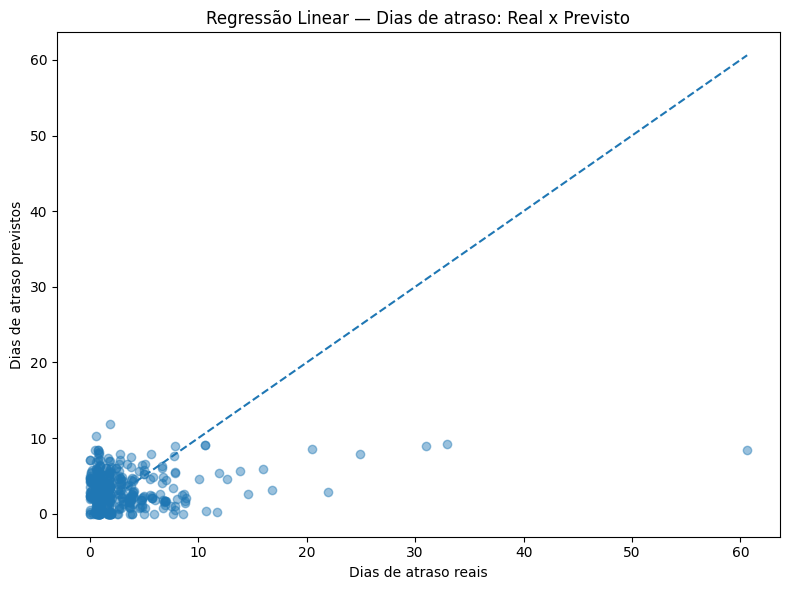

In [40]:
# Comparação Real x Previsto no conjunto de teste
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_test_operacional, alpha=0.45)
lim_max = max(float(y_test.max()), float(y_pred_test_operacional.max()))
plt.plot([0, lim_max], [0, lim_max], linestyle="--")
plt.xlabel("Dias de atraso reais")
plt.ylabel("Dias de atraso previstos")
plt.title("Regressão Linear — Dias de atraso: Real x Previsto")
plt.tight_layout()
plt.show()


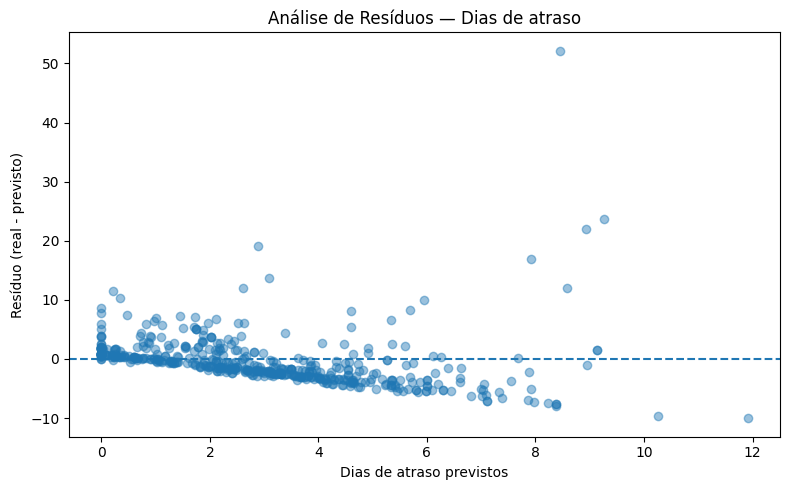

In [41]:
# Resíduos no teste
residuos = y_test.values - y_pred_test_operacional
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test_operacional, residuos, alpha=0.45)
plt.axhline(0, linestyle="--")
plt.xlabel("Dias de atraso previstos")
plt.ylabel("Resíduo (real - previsto)")
plt.title("Análise de Resíduos — Dias de atraso")
plt.tight_layout()
plt.show()


,feature,coeficiente,coef_abs
4,days_since_last_ecommerce_event,-1.7744,1.7744
9,had_ecommerce_event_14_days_ago,-1.6357,1.6357
18,prazo_transportadora_dias,1.4409,1.4409
1,days_since_last_holiday,-0.9947,0.9947
19,carrier_month,-0.9693,0.9693
8,had_ecommerce_event_7_days_ago,0.9505,0.9505
7,is_ecommerce_event_in_14_days,-0.7915,0.7915
17,same_city,-0.7688,0.7688
5,days_until_next_ecommerce_event,-0.7648,0.7648
21,frete_por_kg,0.7087,0.7087


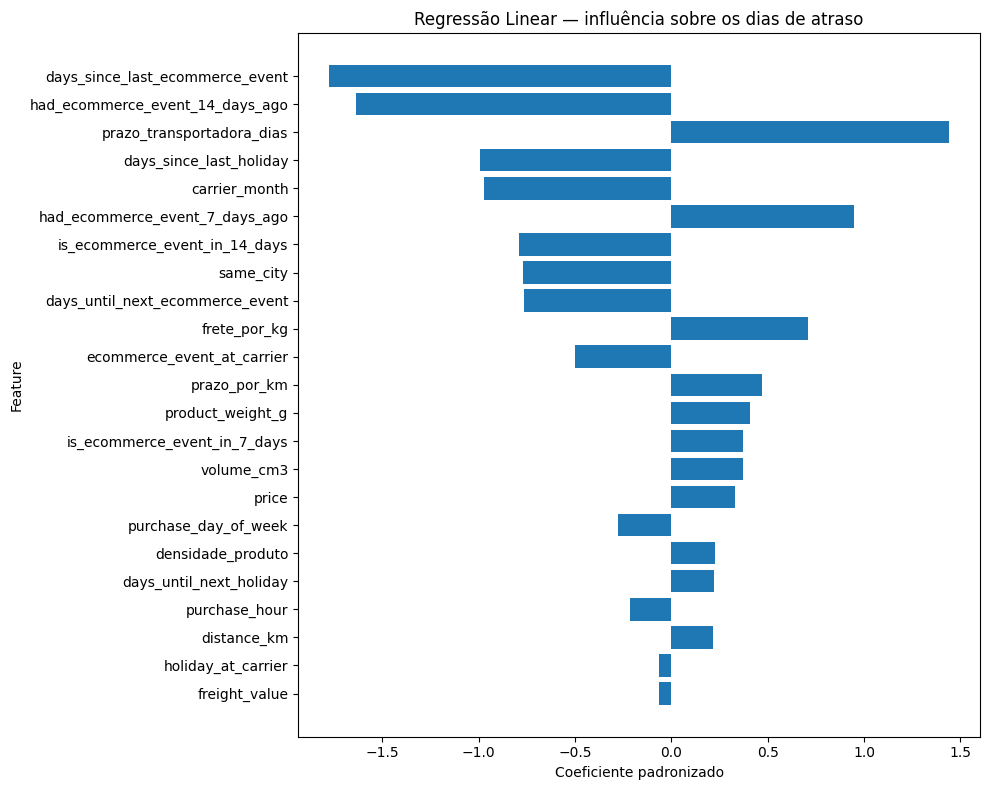

In [42]:
# Coeficientes das features
coeficientes = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "coeficiente": modelo.coef_,
})
coeficientes["coef_abs"] = coeficientes["coeficiente"].abs()
coeficientes = coeficientes.sort_values("coef_abs", ascending=False)
display(coeficientes.round(4))

coef_plot = coeficientes.sort_values("coef_abs", ascending=True)
plt.figure(figsize=(10, 8))
plt.barh(coef_plot["feature"], coef_plot["coeficiente"])
plt.xlabel("Coeficiente padronizado")
plt.ylabel("Feature")
plt.title("Regressão Linear — influência sobre os dias de atraso")
plt.tight_layout()
plt.show()


In [43]:
# Exemplo das previsões do teste
resultado_teste = pd.DataFrame({
    "dias_atraso_real": y_test.values,
    "dias_atraso_previsto": y_pred_test_operacional,
})
resultado_teste["erro_absoluto_dias"] = (
    resultado_teste["dias_atraso_real"] - resultado_teste["dias_atraso_previsto"]
).abs()

display(resultado_teste.head(20).round(2))


,dias_atraso_real,dias_atraso_previsto,erro_absoluto_dias
0,0.8000,3.8700,3.0700
1,0.8300,2.6900,1.8600
2,0.8300,2.6900,1.8600
3,0.6500,5.6600,5.0100
4,7.7800,7.6800,0.1100
5,60.6100,8.4500,52.1600
6,0.7400,7.3800,6.6400
7,7.9000,8.9600,1.0600
8,31.0000,8.9400,22.0700
9,24.9100,7.9100,16.9900


In [44]:
# Célula 11: exportação do modelo e pré-processamento para o backend
artefato_modelo = {
    "model": modelo,
    "scaler": scaler,
    "feature_columns": list(X_train_scaled.columns),
    "target": "delay_days",
    "target_definition": "Diferença entre entrega real e estimada, em dias",
    "training_scope": "somente pedidos com delay_days > 0",
    "train_medians": train_medians,
    "split_date": split_date,
    "clip_prediction_min_zero": True,
    "excluded_columns": colunas_remover,
}
nome_arquivo_modelo = "regressao_linear.pkl"
with open(nome_arquivo_modelo, "wb") as file:
    pickle.dump(artefato_modelo, file)
print(f"Modelo salvo: {nome_arquivo_modelo}")

# Amostra com features de entrada (não escalonadas), mais o resultado real e previsto
n_registros = 100
df_export = X_test.head(n_registros).copy()
df_export["delay_days_real"] = y_test.head(n_registros).values
df_export["delay_days_previsto"] = y_pred_test_operacional[:n_registros].round(4)
nome_csv = f"amostra_regressao_atraso_{n_registros}_pedidos.csv"
df_export.to_csv(nome_csv, index=False)
print(f"Amostra salva: {nome_csv}")


Modelo salvo: regressao_linear.pkl
Amostra salva: amostra_regressao_atraso_100_pedidos.csv
